In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [3]:
import os
dataset_dir = '/content/drive/MyDrive/Colab Notebooks/cat vs dog imgCls/PetImages'
print(os.listdir(dataset_dir))

['Cat', 'Dog']


In [4]:
import os

cat_dir = "/content/drive/MyDrive/Colab Notebooks/cat vs dog imgCls/PetImages/Cat"
dog_dir = "/content/drive/MyDrive/Colab Notebooks/cat vs dog imgCls/PetImages/Dog"

In [5]:
import os
from PIL import Image

# count Cat images
cat_images = [
    file for file in os.listdir(cat_dir)
    if file.lower().endswith((".jpg"))
]

#count  Dog images
dog_images = [
    file for file in os.listdir(dog_dir)
    if file.lower().endswith((".jpg"))
]

print("Number of Cat images:", len(cat_images))
print("Number of Dog images:", len(dog_images))
print("Total images:", len(cat_images) + len(dog_images))

Number of Cat images: 12516
Number of Dog images: 12499
Total images: 25015


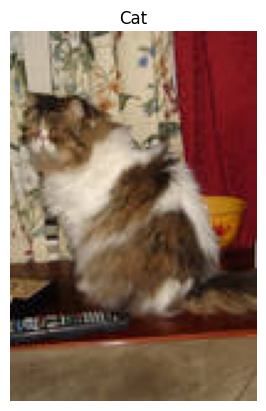

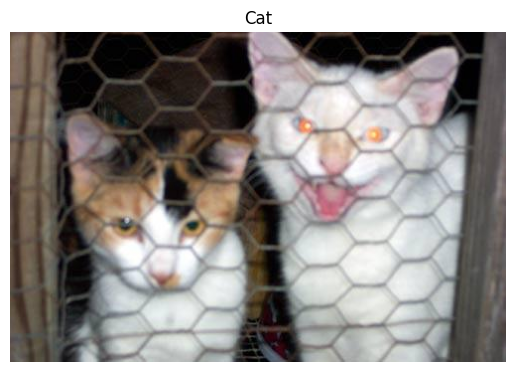

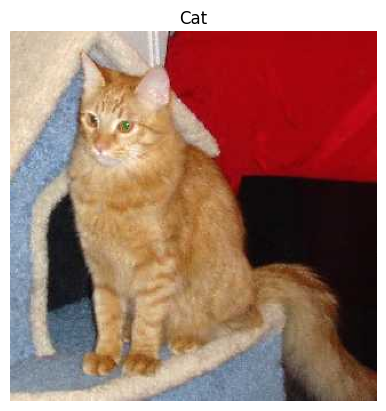

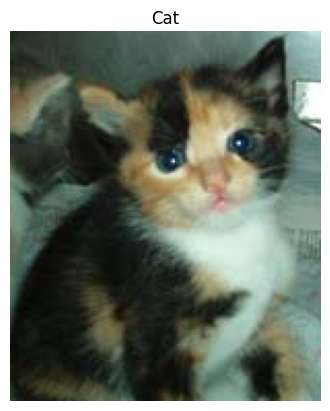

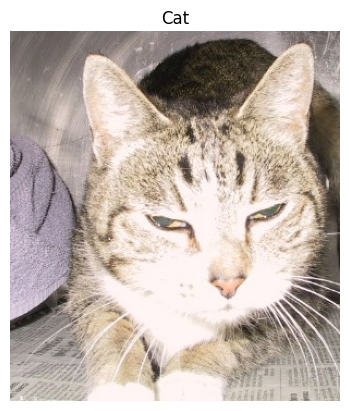

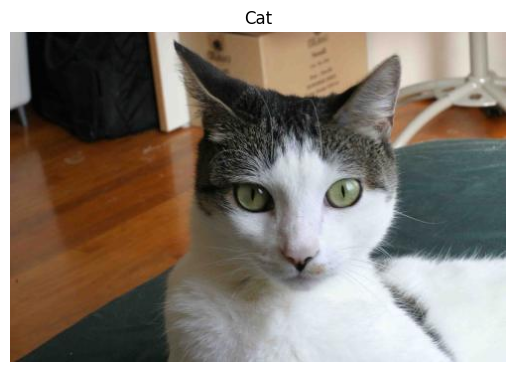

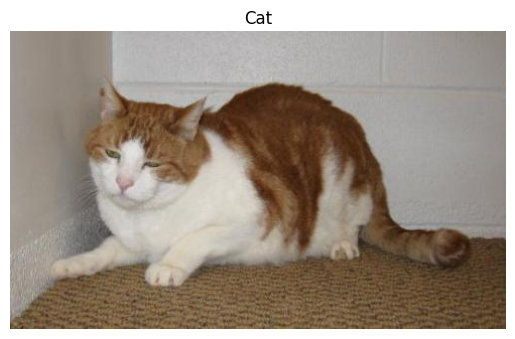

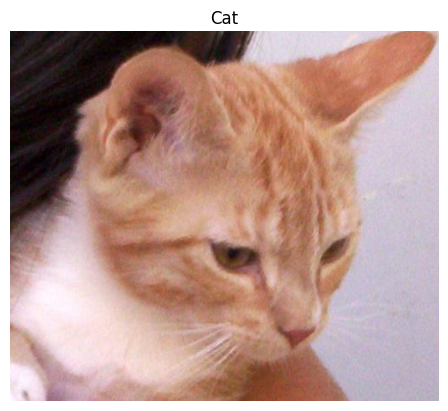

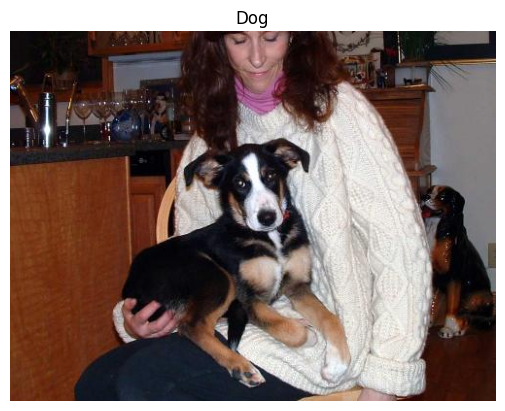

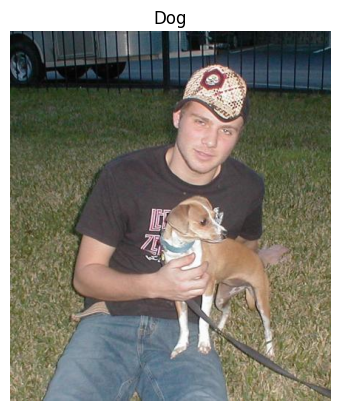

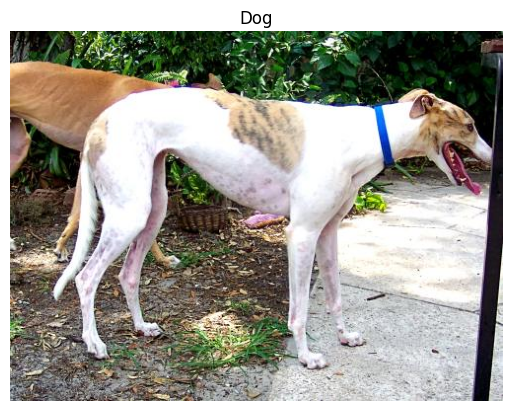

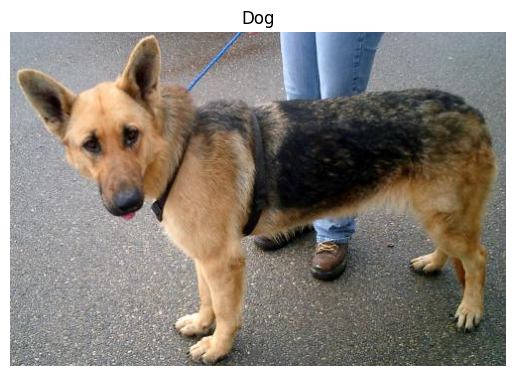

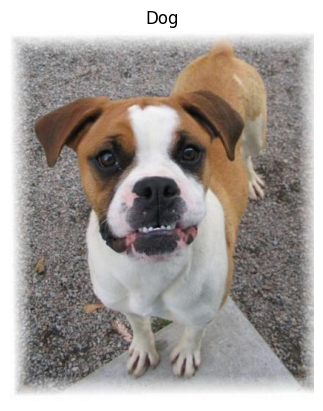

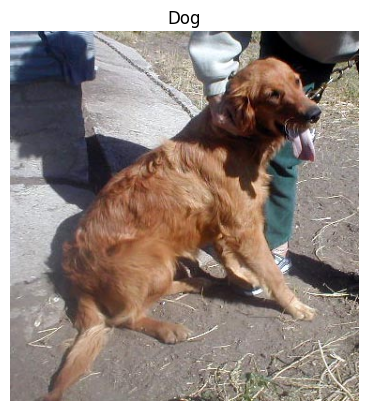

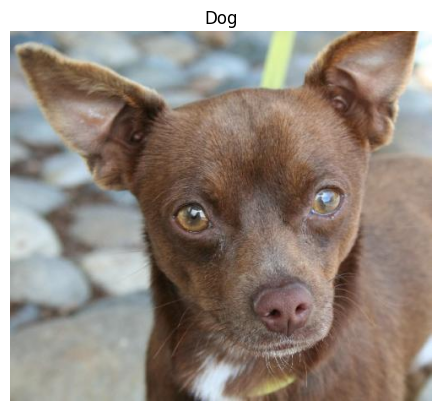

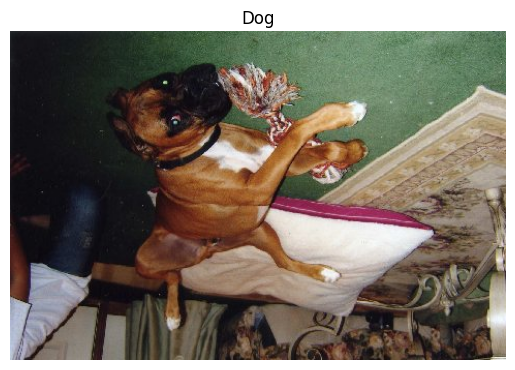

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# Show 8 Cat images
for i in range(8):
    img = Image.open(os.path.join(cat_dir, cat_images[i]))
    plt.imshow(img)
    plt.title("Cat")
    plt.axis("off")
    plt.show()

# Show 8 Dog images
for i in range(8):
    img = Image.open(os.path.join(dog_dir, dog_images[i]))
    plt.imshow(img)
    plt.title("Dog")
    plt.axis("off")
    plt.show()

In [7]:
##Normalize images
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1./255)

In [8]:
train_data = datagen.flow_from_directory(
    "/content/drive/MyDrive/Colab Notebooks/cat vs dog imgCls/PetImages",
    target_size=(160, 160),## resize images
    batch_size=32, # Load 32 images at a time
    class_mode="binary" # Use Cat/Dog classes
)

Found 25015 images belonging to 2 classes.


In [9]:
## Import mobilenetV2 model
from tensorflow.keras.applications import MobileNetV2

In [10]:
main_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

In [11]:
## Freeze model
main_model.trainable = False

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
##Extract features
main_model = Sequential([
    main_model,
    GlobalAveragePooling2D(),
    Dense(1, activation="sigmoid") ##make decision of cat & dog
])

In [13]:
## compile model
main_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [16]:
# Training model
history = main_model.fit(
    train_data,
    epochs=3
)

Epoch 1/3
782/782 ━━━━━━━━━━━━━━━━━━━━ 742s 948ms/step - accuracy: 0.9822 - loss: 0.0500
Epoch 2/3
782/782 ━━━━━━━━━━━━━━━━━━━━ 745s 953ms/step - accuracy: 0.9831 - loss: 0.0471
Epoch 3/3
782/782 ━━━━━━━━━━━━━━━━━━━━ 745s 953ms/step - accuracy: 0.9838 - loss: 0.0447


In [ ]:
# Show accuracy and loss for each epoch
for i in range(5):
    print(
        "Epoch", i + 1,
        "Accuracy:", history.history["accuracy"][i],
        "Loss:", history.history["loss"][i]
    )

In [22]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np

# Upload an image
uploaded = files.upload()

# Get the uploaded image
file_name = list(uploaded.keys())[0]

# Prepare the image
img = image.load_img(
    file_name,
    target_size=(160, 160)
)

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = main_model.predict(img_array)[0][0]

# Show result
if prediction >= 0.5:
    print("Prediction: Dog 🐶")
    print("Confidence:", round(prediction * 100, 2), "%")
else:
    print("Prediction: Cat 🐱")
    print("Confidence:", round((1 - prediction) * 100, 2), "%")

Saving portrait-beautiful-purebred-pussycat-with-shorthair-orange-collar-neck-sitting-floor-reacting-camera-flash-scared-looking-light-indoor_8353-12551.avif to portrait-beautiful-purebred-pussycat-with-shorthair-orange-collar-neck-sitting-floor-reacting-camera-flash-scared-looking-light-indoor_8353-12551 (4).avif
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Prediction: Cat 🐱
Confidence: 100.0 %
